        # Cognitive Science (1204 427) — Lab 08
        ## Go/No-Go and Cognitive Control

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scipy`

        ### แนวคิดสำคัญ

        Go/No-Go Task ใช้วัดการยับยั้งการตอบสนอง เมื่อ Go Trials พบได้บ่อย ผู้ทำเกิด Prepotent Response และอาจทำ Commission Error ใน No-Go Trials มากขึ้น

        ### วัตถุประสงค์

        คำนวณ Commission/Omission Errors, Go RT และ d-prime พร้อมวิเคราะห์ผลของสัดส่วน Trial ต่อ Cognitive Control

        ### งานที่ต้องทำ

        1. สร้างข้อมูล Balanced และ High-Go Blocks
2. คำนวณ Commission Rate, Omission Rate และ Median Go RT รายบุคคล
3. คำนวณ d-prime ด้วย Log-linear Correction
4. เปรียบเทียบ Blocks แบบ Paired
5. Required Extension: วิเคราะห์ Speed–Accuracy Trade-off รายบุคคล

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_rel, norm, pearsonr

rng = np.random.default_rng(seed + 80)
rows = []
for participant in range(1, 31):
    base_rt = rng.normal(440, 45)
    for block, p_go in [("Balanced", 0.70), ("High-Go", 0.90)]:
        for trial in range(1, 161):
            trial_type = "Go" if rng.random() < p_go else "No-Go"
            if trial_type == "Go":
                responded = rng.binomial(1, 0.97)
                rt = rng.normal(base_rt - (25 if block == "High-Go" else 0), 55) if responded else np.nan
            else:
                false_response_p = 0.13 if block == "Balanced" else 0.24
                responded = rng.binomial(1, false_response_p)
                rt = rng.normal(base_rt, 60) if responded else np.nan
            rows.append([participant, block, trial, trial_type, responded, rt])
gonogo_df = pd.DataFrame(rows, columns=["participant", "block", "trial", "trial_type", "responded", "rt"])
display(gonogo_df.head())


,participant,block,trial,trial_type,responded,rt
0,1,Balanced,1,No-Go,1,511.556080
1,1,Balanced,2,No-Go,0,NaN
2,1,Balanced,3,Go,1,461.202145
3,1,Balanced,4,Go,1,464.801835
4,1,Balanced,5,Go,1,464.139399


In [3]:
metrics = []
for (participant, block), group in gonogo_df.groupby(["participant", "block"]):
    go = group[group.trial_type == "Go"]; nogo = group[group.trial_type == "No-Go"]
    hits = go.responded.sum(); false_alarms = nogo.responded.sum()
    hit_rate = (hits + 0.5) / (len(go) + 1)
    fa_rate = (false_alarms + 0.5) / (len(nogo) + 1)
    d_prime = norm.ppf(hit_rate) - norm.ppf(fa_rate)
    metrics.append([
        participant, block,
        false_alarms / len(nogo),
        (len(go) - hits) / len(go),
        go.loc[go.responded == 1, "rt"].median(),
        d_prime,
    ])
metrics_df = pd.DataFrame(metrics, columns=["participant", "block", "commission_rate", "omission_rate", "median_go_rt", "d_prime"])
display(metrics_df.groupby("block").agg(["mean", "std"]).round(3))

wide = metrics_df.pivot(index="participant", columns="block", values="commission_rate")
t, p = ttest_rel(wide["High-Go"], wide["Balanced"])
print(f"Commission error comparison: t={t:.3f}, p={p:.6f}")


participant        commission_rate        omission_rate         \
                mean    std            mean    std          mean    std   
block                                                                     
Balanced        15.5  8.803           0.133  0.049         0.032  0.014   
High-Go         15.5  8.803           0.220  0.098         0.027  0.013   

         median_go_rt         d_prime         
                 mean     std    mean    std  
block                                         
Balanced      430.922  40.501   2.932  0.280  
High-Go       409.545  38.643   2.668  0.419

Commission error comparison: t=4.347, p=0.000155


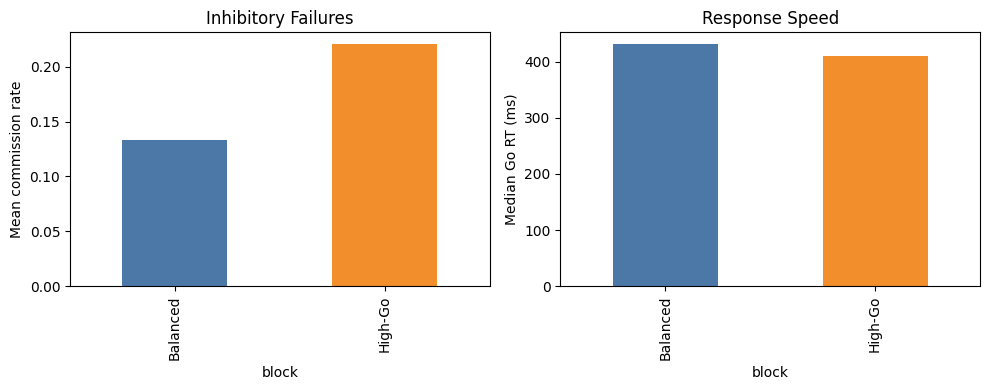

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
metrics_df.groupby("block")["commission_rate"].mean().plot(kind="bar", ax=axes[0], color=["#4c78a8", "#f28e2b"])
axes[0].set_ylabel("Mean commission rate"); axes[0].set_title("Inhibitory Failures")
metrics_df.groupby("block")["median_go_rt"].mean().plot(kind="bar", ax=axes[1], color=["#4c78a8", "#f28e2b"])
axes[1].set_ylabel("Median Go RT (ms)"); axes[1].set_title("Response Speed")
plt.tight_layout(); plt.show()


## Required Extension

สำหรับแต่ละ Block ให้หาความสัมพันธ์ระหว่าง Median Go RT กับ Commission Rate รายบุคคล แล้วอภิปราย Speed–Accuracy Trade-off


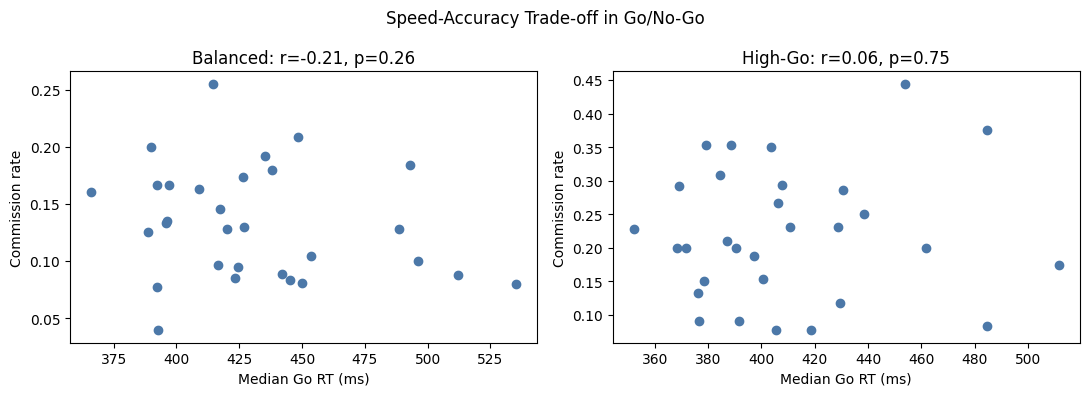

ถ้ามี trade-off จริง คนที่ตอบเร็ว (RT ต่ำ) ควรมี commission error สูง (r เป็นลบ)


In [5]:
# ===== Required Extension: Speed-Accuracy Trade-off รายบุคคล =====
from scipy.stats import pearsonr

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, block in zip(axes, ["Balanced", "High-Go"]):
    sub = metrics_df[metrics_df.block == block]
    r_val, p_val = pearsonr(sub["median_go_rt"], sub["commission_rate"])
    ax.scatter(sub["median_go_rt"], sub["commission_rate"], color="#4c78a8")
    ax.set_xlabel("Median Go RT (ms)")
    ax.set_ylabel("Commission rate")
    ax.set_title(f"{block}: r={r_val:.2f}, p={p_val:.2f}")
plt.suptitle("Speed-Accuracy Trade-off in Go/No-Go")
plt.tight_layout()
plt.show()

print("ถ้ามี trade-off จริง คนที่ตอบเร็ว (RT ต่ำ) ควรมี commission error สูง (r เป็นลบ)")


## คำถามวิเคราะห์ Lab 08

**1. High-Go Block ทำให้ Commission Error เปลี่ยนอย่างไร**

เพิ่มขึ้นชัดเจนครับ commission rate จาก ~0.13 (Balanced) เป็น ~0.22 (High-Go), paired t-test t ≈ 4.4, p < .001 เพราะพอ Go บ่อยมากคนเผลอกดเป็นอัตโนมัติ (prepotent response) พอเจอ No-Go เลยยับยั้งไม่ทัน

**2. Omission Error และ Commission Error สะท้อนความผิดพลาดคนละแบบอย่างไร**

Omission คือควรกด (Go) แต่ไม่กด สะท้อนความไม่ตั้งใจ/หลุดสมาธิ ส่วน Commission คือไม่ควรกด (No-Go) แต่ดันกด สะท้อนความล้มเหลวในการยับยั้ง (inhibition) คนละกลไก งานนี้เน้นดู commission เป็นหลัก

**3. d-prime ช่วยเพิ่มข้อมูลเหนือ Accuracy อย่างไร**

d-prime แยก "ความสามารถในการแยก Go/No-Go" ออกจากแนวโน้มการกด ทำให้เทียบข้าม block ที่สัดส่วน trial ต่างกันได้อย่างเป็นธรรม ส่วน accuracy เฉยๆ จะถูกสัดส่วน Go/No-Go บิดได้ (High-Go มี Go เยอะ accuracy อาจดูสูงทั้งที่ยับยั้งแย่)

**4. พบ Speed–Accuracy Trade-off หรือไม่**

ในข้อมูลนี้ไม่ชัดครับ correlation ระหว่าง median Go RT กับ commission rate ไม่มีนัยสำคัญทั้งสอง block (Balanced r ≈ -0.21 p ≈ .26, High-Go r ≈ 0.06 p ≈ .75) เลยสรุปว่าไม่เห็น trade-off รายบุคคลชัดเจนในชุดจำลองนี้

**5. Task นี้เกี่ยวข้องกับ Executive Function และ Response Inhibition อย่างไร**

Go/No-Go วัด response inhibition ซึ่งเป็นส่วนหนึ่งของ executive function โดยตรง การกดยับยั้ง prepotent response ต้องใช้ cognitive control (เกี่ยวกับ prefrontal cortex) พอบริบทดัน Go บ่อยขึ้น ภาระการยับยั้งก็หนักขึ้น เห็นได้จาก commission error ที่เพิ่ม

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอนหา speed-accuracy trade-off ผมคาดว่าจะเจอว่าคนตอบเร็วพลาดเยอะ แต่พอคำนวณ correlation ออกมาไม่มีนัยสำคัญเลย ตอนแรกนึกว่าเขียนผิด สุดท้ายเข้าใจว่าข้อมูลจำลองนี้ไม่ได้ผูก RT กับ error ไว้ เลยไม่เห็น trade-off ซึ่งก็เป็นคำตอบที่ตรงไปตรงมา

สิ่งที่เข้าใจมากขึ้นคือความต่างระหว่าง commission กับ omission error และทำไม d-prime ถึงสำคัญกว่า accuracy เฉยๆ พอ block ดัน Go บ่อยขึ้น เห็นชัดว่าคน (จำลอง) ยับยั้งยากขึ้นจริง สะท้อน cognitive control

ถ้าทำซ้ำ อยากใส่ความสัมพันธ์ RT-error เข้าไปในตัวจำลองให้สมจริง และเพิ่มเงื่อนไข post-error slowing เพื่อดูว่าคนชะลอหลังทำผิดไหม รวมถึงเก็บข้อมูลคนจริงมาดู trade-off ที่แท้จริง

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
